# Qwen3 repaired-reconstruction boxplots

Paper-ready grouped boxplots for the seven metrics in the GUI reconstruction table. Each pooling group contains the Qwen3-0.6B-Base, Qwen3-1.7B-Base, and Qwen3-4B-Base decoders.

Every available raw reconstruction is parsed, repaired when necessary, has degenerate component loops collapsed, and is rescored with the repository's shared `repair_rescore.py` / `reconstruction_metrics.py` implementation. Strict and repaired values are never mixed. Incomplete runs are included by default because they are the only currently available observations for some 4B conditions; their sample counts and completion status are printed below.

The final cell exports one vector PDF per metric to `overleaf/graphics/`. Figure dimensions and the other paper-style controls live together in the configuration cell.

In [29]:
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path
import json
import re
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from tqdm.auto import tqdm

import repair_rescore

# ------------------------------ Analysis configuration -----------------------
MODEL_SIZES = [0.6, 1.7, 4.0]
MODEL_LABELS = {0.6: "Qwen3 0.6B", 1.7: "Qwen3 1.7B", 4.0: "Qwen3 4B"}
POOL_ORDER = ["4096_last", "4096_avg", "4x4096_avg", "16x4096_avg", "64x4096_avg"]
POOL_LABELS = {
    "4096_last": "4096 last",
    "4096_avg": "4096 avg",
    "4x4096_avg": "4×4096 avg",
    "16x4096_avg": "16×4096 avg",
    "64x4096_avg": "64×4096 avg",
}
RICO_LAYOUT_DIR = Path("../rico-data/data/layouts")
COLLAPSE_LOOPS = True
MAX_WORKERS = None             # None uses all logical CPU cores.
CHUNKSIZE = 8
INCLUDE_INCOMPLETE = True      # Keep partial 4B runs in the plots.
FORCE_RESCORE = False          # True ignores a valid cache and repairs again.
CACHE_PATH = Path("graphics/qwen3_repaired_boxplot_metrics.csv.gz")
CACHE_META_PATH = CACHE_PATH.with_suffix(".meta.json")
CACHE_SCHEMA_VERSION = 1

# -------------------------------- Figure configuration -----------------------
PDF_DIR = Path("overleaf/graphics")
PDF_PREFIX = "qwen3_repaired"
FIGSIZE = (4.75, 2.75)           # inches; change only this for paper sizing.
DPI = 150                      # notebook display only; PDFs remain vector.
SHOW_FLIERS = False            # avoids huge PDFs for ~66k-screen runs.
BOX_WIDTH = 0.72
LINE_WIDTH = 0.8
MIN_BOXPLOT_N = 20             # refuse meaningless one/few-sample boxes.
SHOW_TITLES = False            # captions usually replace titles in LaTeX.
PALETTE = {
    "Qwen3 0.6B": "#4C78A8",
    "Qwen3 1.7B": "#F58518",
    "Qwen3 4B": "#54A24B",
}

sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({
    "figure.dpi": DPI,
    "savefig.dpi": DPI,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

## Metrics and Qwen3 experiment discovery

The directory expression intentionally accepts only the five pooling strategies and three Qwen3 Base decoders in the table. It excludes Qwen2.5, Qwen3.5, and the separate non-Base `qwen3-1.7b` artifact.

In [2]:
METRIC_SPECS = {
    "class_accuracy_repaired": {
        "label": "Class accuracy (strict pairing)", "slug": "class_accuracy", "ylim": (0, 1),
    },
    "class_unordered_f1_repaired": {
        "label": "Class accuracy (unordered F1)", "slug": "class_accuracy_unordered", "ylim": (0, 1),
    },
    "class_level_f1_repaired": {
        "label": "Class accuracy (depth-aware F1)", "slug": "class_accuracy_depth_aware", "ylim": (0, 1),
    },
    "levenshtein_similarity_repaired": {
        "label": "Levenshtein similarity", "slug": "levenshtein_similarity", "ylim": (0, 1),
    },
    "levenshtein_distance_repaired": {
        "label": "Levenshtein distance", "slug": "levenshtein_distance", "ylim": None,
    },
    "average_bounds_iou_repaired": {
        "label": "Average bounds IoU", "slug": "average_bounds_iou", "ylim": (0, 1),
    },
    "matched_iou_repaired": {
        "label": "Matched bounds IoU", "slug": "matched_bounds_iou", "ylim": (0, 1),
    },
}

experiment_re = re.compile(
    r"^reconstructions_(?P<pool>4096_(?:last|avg)|(?:4|16|64)x4096_avg)"
    r"__via__embeddings_(?P=pool)_full_qwen3-(?P<size>0\.6|1\.7|4)b-base$"
)

experiment_rows = []
prediction_files = {}
for directory in Path(".").glob("reconstructions_*qwen3-*-base"):
    match = experiment_re.fullmatch(directory.name)
    if match is None:
        continue
    pooling = match.group("pool")
    model_size = float(match.group("size"))
    dim = directory.name.removeprefix("reconstructions_")
    files = {
        path.name.removesuffix("_reconstructed.json"): path
        for path in directory.glob("*_reconstructed.json")
    }
    prediction_files[dim] = files
    experiment_rows.append({
        "dim": dim, "pooling": pooling, "model_size_b": model_size,
        "model_label": MODEL_LABELS[model_size], "directory": directory,
        "n_screens": len(files),
        "latest_mtime_ns": max((p.stat().st_mtime_ns for p in files.values()), default=0),
    })

experiments = pd.DataFrame(experiment_rows)
if experiments.empty:
    raise FileNotFoundError("No Qwen3 Base reconstruction directories were found. Run from the repository root.")
if experiments.duplicated(["pooling", "model_size_b"]).any():
    raise ValueError("More than one directory matched a Qwen3 pooling/model condition.")

expected_conditions = {(pool, size) for pool in POOL_ORDER for size in MODEL_SIZES}
found_conditions = set(zip(experiments["pooling"], experiments["model_size_b"]))
missing_conditions = expected_conditions - found_conditions
if missing_conditions:
    warnings.warn(f"Missing reconstruction directories: {sorted(missing_conditions)}")

def expected_screen_count(row):
    # The table documents the one completed run with a single missing screen.
    if row.pooling == "4x4096_avg" and row.model_size_b == 1.7:
        return 66_260
    return 66_261

experiments["expected_screens"] = [expected_screen_count(row) for row in experiments.itertuples()]
experiments["complete"] = experiments["n_screens"] >= experiments["expected_screens"]
experiments["status"] = experiments["complete"].map({True: "complete", False: "incomplete (partial)"})
experiments["pool_order"] = experiments["pooling"].map({name: i for i, name in enumerate(POOL_ORDER)})
experiments = experiments.sort_values(["pool_order", "model_size_b"]).reset_index(drop=True)

run_inventory = experiments[["pooling", "model_label", "n_screens", "expected_screens", "status"]]
print(run_inventory.to_string(index=False))

    pooling model_label  n_screens  expected_screens               status
  4096_last  Qwen3 0.6B      66261             66261             complete
  4096_last  Qwen3 1.7B      33733             66261 incomplete (partial)
  4096_last    Qwen3 4B      60053             66261 incomplete (partial)
   4096_avg  Qwen3 0.6B      66261             66261             complete
   4096_avg  Qwen3 1.7B      66261             66261             complete
   4096_avg    Qwen3 4B      61013             66261 incomplete (partial)
 4x4096_avg  Qwen3 0.6B      66261             66261             complete
 4x4096_avg  Qwen3 1.7B      66260             66260             complete
 4x4096_avg    Qwen3 4B      64533             66261 incomplete (partial)
16x4096_avg  Qwen3 0.6B      66261             66261             complete
16x4096_avg  Qwen3 1.7B      66261             66261             complete
16x4096_avg    Qwen3 4B      62997             66261 incomplete (partial)
64x4096_avg  Qwen3 0.6B      66261    

## Repair and rescore every available prediction

This is deliberately a complete pass (`only_invalid=False` in the older notebook's terminology): valid JSON can still contain repetition loops. Work is grouped by RICO screen so its cleaned ground truth is loaded once and shared across all available Qwen3 conditions.

A compressed cache is reused only when the repair settings and every source directory's file count/latest modification time still match. Set `FORCE_RESCORE=True` above to bypass it.

In [3]:
if not RICO_LAYOUT_DIR.is_dir():
    raise FileNotFoundError(f"RICO layouts not found at {RICO_LAYOUT_DIR.resolve()}")

inventory_signature = {
    row.dim: {"count": int(row.n_screens), "latest_mtime_ns": int(row.latest_mtime_ns)}
    for row in experiments.itertuples(index=False)
}
wanted_metadata = {
    "schema_version": CACHE_SCHEMA_VERSION,
    "collapse_loops": COLLAPSE_LOOPS,
    "inventory": inventory_signature,
}

cache_is_current = False
if not FORCE_RESCORE and CACHE_PATH.is_file() and CACHE_META_PATH.is_file():
    try:
        cache_is_current = json.loads(CACHE_META_PATH.read_text(encoding="utf-8")) == wanted_metadata
    except (OSError, json.JSONDecodeError):
        cache_is_current = False

if cache_is_current:
    repaired = pd.read_csv(CACHE_PATH, dtype={"dim": str, "idx": str})
    print(f"Loaded {len(repaired):,} repaired rows from {CACHE_PATH}")
else:
    all_screen_ids = sorted(
        set().union(*(set(files) for files in prediction_files.values())), key=int
    )
    tasks = []
    for screen_id in all_screen_ids:
        entries = [
            (dim, str(files[screen_id]))
            for dim, files in prediction_files.items()
            if screen_id in files
        ]
        tasks.append((screen_id, str(RICO_LAYOUT_DIR / f"{screen_id}.json"), entries))

    n_predictions = sum(len(task[2]) for task in tasks)
    print(f"Repairing and rescoring {n_predictions:,} predictions across {len(tasks):,} screens")
    repaired_rows = []
    with ProcessPoolExecutor(
        max_workers=MAX_WORKERS,
        initializer=repair_rescore.init_worker,
        initargs=(COLLAPSE_LOOPS,),
    ) as pool:
        for screen_rows in tqdm(
            pool.map(repair_rescore.rescore_item, tasks, chunksize=CHUNKSIZE),
            total=len(tasks), desc="repair + rescore",
        ):
            repaired_rows.extend(screen_rows)

    repaired = pd.DataFrame(repaired_rows)
    if "rescore_error" in repaired.columns:
        failures = repaired[repaired["rescore_error"].notna()]
        if not failures.empty:
            raise RuntimeError(f"{len(failures)} predictions could not be rescored:\n{failures.head()}")
    repaired["idx"] = repaired["idx"].astype(str)
    keep_columns = [
        "dim", "idx", "json_valid_repaired", "json_repair_used", "components_collapsed",
        *METRIC_SPECS.keys(),
    ]
    repaired = repaired[keep_columns]
    CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
    repaired.to_csv(CACHE_PATH, index=False, compression="gzip")
    CACHE_META_PATH.write_text(json.dumps(wanted_metadata, indent=2), encoding="utf-8")
    print(f"Cached {len(repaired):,} repaired rows at {CACHE_PATH}")

expected_rows = int(experiments["n_screens"].sum())
if len(repaired) != expected_rows:
    raise AssertionError(f"Expected {expected_rows:,} rows, found {len(repaired):,}")

Repairing and rescoring 917,300 predictions across 66,261 screens


repair + rescore: 100%|██████████████████████████████████████████████████████████| 66261/66261 [26:54<00:00, 41.05it/s]


Cached 917,300 repaired rows at graphics\qwen3_repaired_boxplot_metrics.csv.gz


## Descriptive statistics

The printed table reports the requested per-condition mean, sample SD, median, and IQR (`Q3 − Q1`), plus `n`. The CSV export preserves full precision.

In [4]:
analysis = repaired.merge(
    experiments[["dim", "pooling", "model_size_b", "model_label", "complete", "status"]],
    on="dim", how="left", validate="many_to_one",
)
if analysis["pooling"].isna().any():
    raise AssertionError("Cached rows contain an unrecognized experiment directory.")
for metric in METRIC_SPECS:
    analysis[metric] = pd.to_numeric(analysis[metric], errors="coerce")
if analysis[list(METRIC_SPECS)].isna().any().any():
    missing = analysis[list(METRIC_SPECS)].isna().sum()
    raise AssertionError(f"Missing repaired metric values:\n{missing[missing.gt(0)]}")

analysis["pooling_label"] = pd.Categorical(
    analysis["pooling"].map(POOL_LABELS),
    categories=[POOL_LABELS[name] for name in POOL_ORDER], ordered=True,
)
analysis["model_label"] = pd.Categorical(
    analysis["model_label"],
    categories=[MODEL_LABELS[size] for size in MODEL_SIZES], ordered=True,
)
plot_data = analysis if INCLUDE_INCOMPLETE else analysis[analysis["complete"]].copy()

long_metrics = analysis.melt(
    id_vars=["pooling", "model_size_b", "model_label", "status"],
    value_vars=list(METRIC_SPECS), var_name="metric", value_name="value",
)
descriptive = (
    long_metrics.groupby(
        ["pooling", "model_size_b", "model_label", "status", "metric"],
        observed=True, as_index=False,
    )["value"]
    .agg(
        n="count", mean="mean", sd="std", median="median",
        q1=lambda values: values.quantile(0.25),
        q3=lambda values: values.quantile(0.75),
    )
)
descriptive["iqr"] = descriptive["q3"] - descriptive["q1"]
descriptive["pool_order"] = descriptive["pooling"].map({name: i for i, name in enumerate(POOL_ORDER)})
descriptive = descriptive.sort_values(["metric", "pool_order", "model_size_b"]).drop(columns="pool_order")

PDF_DIR.mkdir(parents=True, exist_ok=True)
stats_path = PDF_DIR / f"{PDF_PREFIX}_descriptive_statistics.csv"
descriptive.to_csv(stats_path, index=False)
for metric, spec in METRIC_SPECS.items():
    print(f"\n{spec['label']}")
    table = descriptive.loc[
        descriptive["metric"].eq(metric),
        ["pooling", "model_label", "status", "n", "mean", "sd", "median", "iqr"],
    ]
    print(table.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
print(f"\nExported full-precision statistics to {stats_path}")


Class accuracy (strict pairing)
    pooling model_label               status     n   mean     sd  median    iqr
  4096_last  Qwen3 0.6B             complete 66261 0.2848 0.3165  0.1875 0.4500
  4096_last  Qwen3 1.7B incomplete (partial) 33733 0.2794 0.3303  0.1538 0.4667
  4096_last    Qwen3 4B incomplete (partial) 60053 0.2856 0.3182  0.1818 0.4615
   4096_avg  Qwen3 0.6B             complete 66261 0.2120 0.2800  0.1053 0.3095
   4096_avg  Qwen3 1.7B             complete 66261 0.2718 0.3008  0.1818 0.4167
   4096_avg    Qwen3 4B incomplete (partial) 61013 0.1259 0.2391  0.0000 0.1429
 4x4096_avg  Qwen3 0.6B             complete 66261 0.3411 0.3289  0.2500 0.4916
 4x4096_avg  Qwen3 1.7B             complete 66260 0.3520 0.3251  0.2745 0.4760
 4x4096_avg    Qwen3 4B incomplete (partial) 64533 0.2419 0.2900  0.1429 0.3636
16x4096_avg  Qwen3 0.6B             complete 66261 0.3857 0.3311  0.3200 0.5000
16x4096_avg  Qwen3 1.7B             complete 66261 0.3808 0.3329  0.3077 0.5062
16x4096

## Seaborn grouped boxplots and PDF export

Boxes use the standard Tukey definition (quartiles with 1.5×IQR whiskers). Outlier markers are hidden by default to keep the vector PDFs compact; this does not change any box or whisker statistic.

Exported overleaf\graphics\qwen3_repaired_class_accuracy_boxplot.pdf


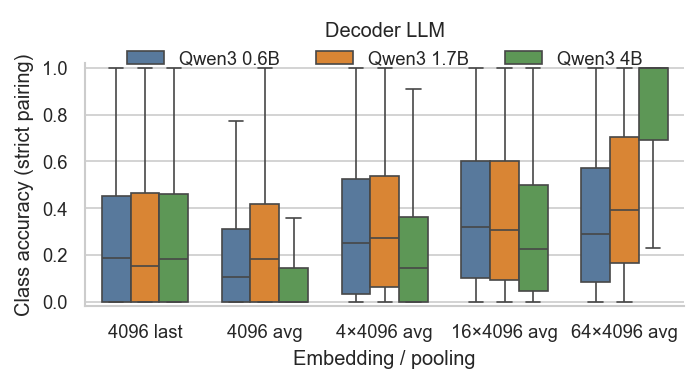

Exported overleaf\graphics\qwen3_repaired_class_accuracy_unordered_boxplot.pdf


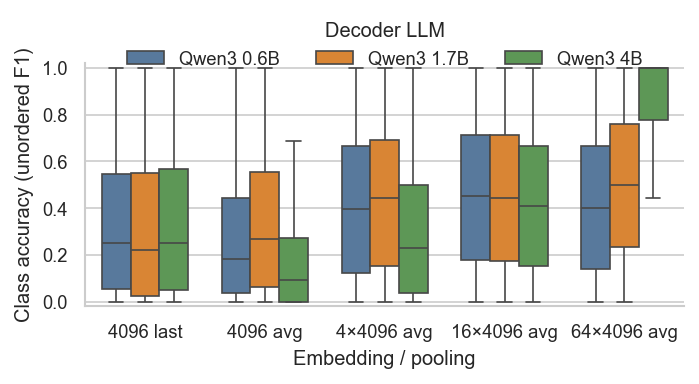

Exported overleaf\graphics\qwen3_repaired_class_accuracy_depth_aware_boxplot.pdf


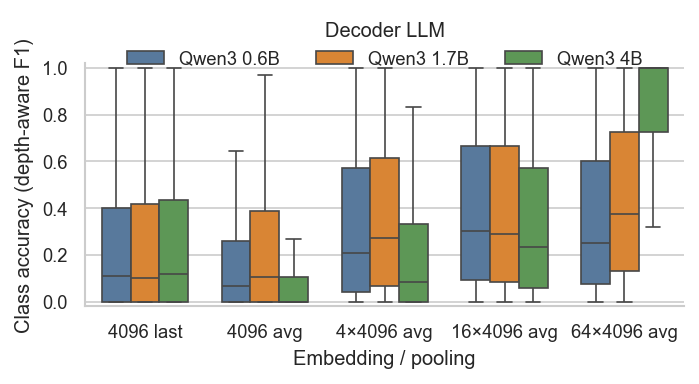

Exported overleaf\graphics\qwen3_repaired_levenshtein_similarity_boxplot.pdf


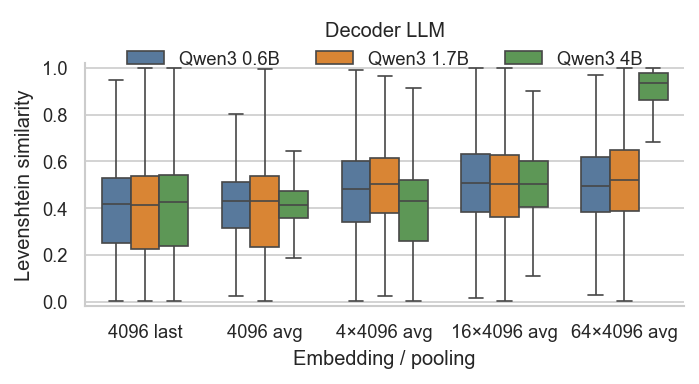

Exported overleaf\graphics\qwen3_repaired_levenshtein_distance_boxplot.pdf


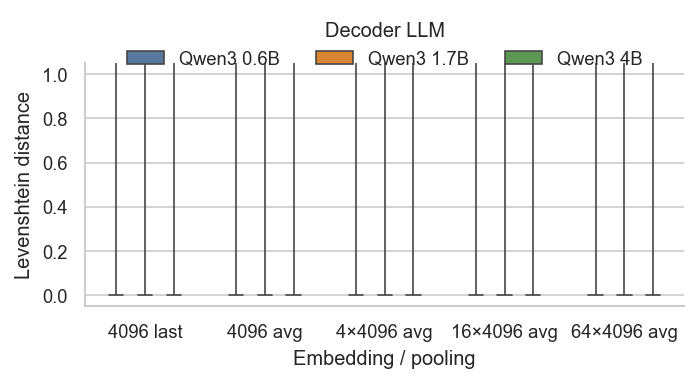

Exported overleaf\graphics\qwen3_repaired_average_bounds_iou_boxplot.pdf


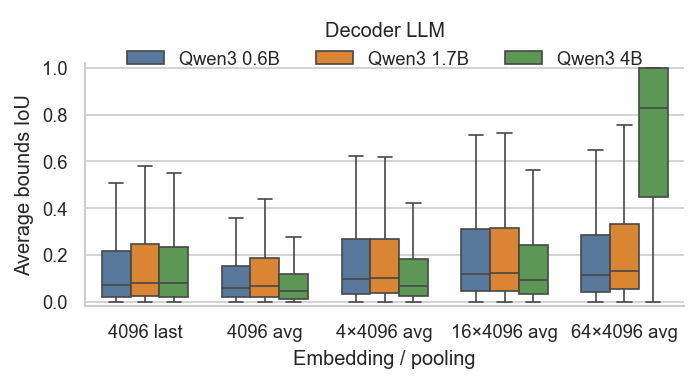

Exported overleaf\graphics\qwen3_repaired_matched_bounds_iou_boxplot.pdf


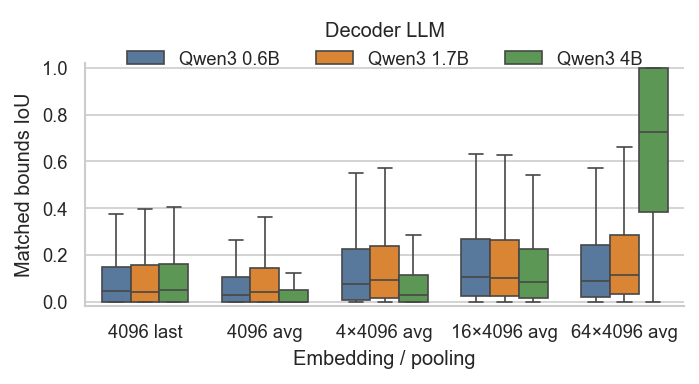


PDF exports:
overleaf\graphics\qwen3_repaired_class_accuracy_boxplot.pdf
overleaf\graphics\qwen3_repaired_class_accuracy_unordered_boxplot.pdf
overleaf\graphics\qwen3_repaired_class_accuracy_depth_aware_boxplot.pdf
overleaf\graphics\qwen3_repaired_levenshtein_similarity_boxplot.pdf
overleaf\graphics\qwen3_repaired_levenshtein_distance_boxplot.pdf
overleaf\graphics\qwen3_repaired_average_bounds_iou_boxplot.pdf
overleaf\graphics\qwen3_repaired_matched_bounds_iou_boxplot.pdf


In [30]:
plot_group_counts = plot_data.groupby(["pooling", "model_label"], observed=True).size()
too_small = plot_group_counts[plot_group_counts.lt(MIN_BOXPLOT_N)]
if not too_small.empty:
    raise ValueError(
        f"Refusing to export boxplots with fewer than {MIN_BOXPLOT_N} observations:\n{too_small}"
    )

Y_PADDING_FRACTION = 0.02


def grouped_boxplot(metric, spec):
    fig, ax = plt.subplots(figsize=FIGSIZE)

    sns.boxplot(
        data=plot_data,
        x="pooling_label",
        y=metric,
        hue="model_label",
        order=[POOL_LABELS[name] for name in POOL_ORDER],
        hue_order=[MODEL_LABELS[size] for size in MODEL_SIZES],
        palette=PALETTE,
        width=BOX_WIDTH,
        linewidth=LINE_WIDTH,
        showfliers=SHOW_FLIERS,
        whis=1.5,
        ax=ax,
    )
    
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel("Embedding / pooling")
    ax.set_ylabel(spec["label"])

    if spec["ylim"] is not None:
        y_min, y_max = spec["ylim"]

        # First use the intended metric range to obtain sensible tick positions.
        ax.set_ylim(y_min, y_max)
        y_ticks = ax.get_yticks()
        y_ticks = y_ticks[(y_ticks >= y_min) & (y_ticks <= y_max)]

        # Add a very small visual margin above and below the metric range.
        y_range = y_max - y_min
        y_pad = Y_PADDING_FRACTION * y_range

        ax.set_ylim(
            y_min - y_pad,
            y_max + y_pad,
        )

        # Keep tick labels restricted to the actual metric range.
        ax.set_yticks(y_ticks)

    if SHOW_TITLES:
        ax.set_title(f"{spec['label']} — repaired reconstructions")

    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="x", visible=False)

    legend = ax.legend(
        title="Decoder LLM",
        loc="upper center",
        bbox_to_anchor=(0.5, 1.20),
        ncol=3,
        frameon=False,
        borderaxespad=0,
    )

    fig.tight_layout()

    output_path = PDF_DIR / f"{PDF_PREFIX}_{spec['slug']}_boxplot.pdf"

    fig.savefig(
        output_path,
        format="pdf",
        bbox_inches="tight",
        metadata={
            "Creator": "Matplotlib + Seaborn",
            "Title": spec["label"],
        },
    )

    print(f"Exported {output_path}")

    return fig, ax, output_path


exported_pdfs = []

for metric, spec in METRIC_SPECS.items():
    fig, ax, output_path = grouped_boxplot(metric, spec)
    exported_pdfs.append(output_path)

    plt.show()
    plt.close(fig)

print("\nPDF exports:")
print("\n".join(str(path) for path in exported_pdfs))

In [6]:
# Generate every table entry from the descriptive statistics computed above.
import math

TABLE_METRICS = [
    "class_accuracy_repaired", "class_unordered_f1_repaired",
    "class_level_f1_repaired", "levenshtein_similarity_repaired",
    "levenshtein_distance_repaired", "average_bounds_iou_repaired",
    "matched_iou_repaired",
]
table_stats = descriptive.set_index(
    ["pooling", "model_size_b", "metric"], verify_integrity=True
)

table_header = r"""\begin{table*}[t]
    \centering
    \caption{GUI reconstruction performance across embedding pooling strategies and decoder LLMs after JSON repair and repetition-loop collapse.
    For each metric, we report the per-screen mean and sample standard deviation (SD).
    Class Accuracy (strict) uses strict component pairing; Class Accuracy (unordered) and Class Accuracy (depth-aware) are the respective F1 scores.}
    \label{tab:gui_reconstruction_results}
    \scriptsize
    \begingroup
    \setlength{\tabcolsep}{2.2pt}
    \renewcommand{\arraystretch}{1.1}
    \resizebox{\linewidth}{!}{%
    \begin{tabular}{@{}ll|*{7}{rr}@{}}
        \toprule
        \textbf{Embedding/Pooling} &
        \textbf{Decoder LLM} &
        \multicolumn{2}{|c}{\shortstack{\textbf{Class Accuracy}\\\textbf{(strict)}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Class Accuracy}\\\textbf{(unordered)}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Class Accuracy}\\\textbf{(depth-aware)}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Levenshtein}\\\textbf{Similarity}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Levenshtein}\\\textbf{Distance}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Average Bounds}\\\textbf{IoU}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Matched Bounds}\\\textbf{IoU}}} \\
        \cmidrule(lr){3-4}
        \cmidrule(lr){5-6}
        \cmidrule(lr){7-8}
        \cmidrule(lr){9-10}
        \cmidrule(lr){11-12}
        \cmidrule(lr){13-14}
        \cmidrule(lr){15-16}
        &
        &
        \multicolumn{1}{|c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} &
        \multicolumn{1}{c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} &
        \multicolumn{1}{c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} &
        \multicolumn{1}{c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} &
        \multicolumn{1}{c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} &
        \multicolumn{1}{c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} &
        \multicolumn{1}{c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} \\
"""

table_rows = []
for pooling in POOL_ORDER:
    table_rows.append(r"        \midrule")
    pooling_tex = pooling.replace("_", r"\_")
    table_rows.append(
        r"        \multirow{" + str(len(MODEL_SIZES))
        + r"}{*}{\texttt{" + pooling_tex + "}}"
    )
    for model_size in MODEL_SIZES:
        table_rows.append(f"            & Qwen3-{model_size:g}B-Base")
        for metric in TABLE_METRICS:
            stats = table_stats.loc[(pooling, model_size, metric)]
            mean, sd = float(stats["mean"]), float(stats["sd"])
            if not all(math.isfinite(value) for value in (mean, sd)):
                raise ValueError(f"Missing mean/SD for {pooling}, {model_size}B, {metric}")
            digits = 2 if metric == "levenshtein_distance_repaired" else 4
            table_rows.append(f"            & {mean:.{digits}f} & {sd:.{digits}f}")
        table_rows[-1] += r" \\"

table_footer = r"""        \bottomrule
    \end{tabular}%
    }
    \endgroup
\end{table*}"""

latex_table = table_header + "\n".join(table_rows) + "\n" + table_footer
print(latex_table)

\begin{table*}[t]
    \centering
    \caption{GUI reconstruction performance across embedding pooling strategies and decoder LLMs after JSON repair and repetition-loop collapse.
    For each metric, we report the per-screen mean and sample standard deviation (SD).
    Class Accuracy (strict) uses strict component pairing; Class Accuracy (unordered) and Class Accuracy (depth-aware) are the respective F1 scores.}
    \label{tab:gui_reconstruction_results}
    \scriptsize
    \begingroup
    \setlength{\tabcolsep}{2.2pt}
    \renewcommand{\arraystretch}{1.1}
    \resizebox{\linewidth}{!}{%
    \begin{tabular}{@{}ll|*{7}{rr}@{}}
        \toprule
        \textbf{Embedding/Pooling} &
        \textbf{Decoder LLM} &
        \multicolumn{2}{|c}{\shortstack{\textbf{Class Accuracy}\\\textbf{(strict)}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Class Accuracy}\\\textbf{(unordered)}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Class Accuracy}\\\textbf{(depth-aware)}}} &
        \multic

C:\Users\Jonathan\AppData\Local\Temp\ipykernel_32064\740608126.py:10: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  table_stats = descriptive.set_index(
